In [ ]:
import pickle
from pathlib import Path

import geopandas as gpd
import numpy as np
import osmnx as ox
import polars as pl
from pyproj import Transformer

transformer = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)

ox.settings.log_console = False
ox.settings.use_cache = True

In [50]:
DIR = "/mnt/common-ssd/group-dirs/tkom-2026-project/pickwell/budapest/partitioned"

In [5]:
area = gpd.read_file("../data/osm/budapest/boundary.geojson")

In [ ]:
try:
    g_drive = ox.load_graphml("../output/budapest/map_matching/drive.graphml")
except FileNotFoundError:
    # 2m 1s
    g_drive = ox.graph_from_polygon(
        area.geometry[0], network_type="drive", simplify=False
    )

    ox.save_graphml(g_drive, "../output/budapest/map_matching/drive.graphml")

In [ ]:
try:
    g_all = ox.load_graphml("../output/budapest/map_matching/all.graphml")
except FileNotFoundError:
    # 4m
    g_all = ox.graph_from_polygon(area.geometry[0], network_type="all", simplify=False)
    ox.save_graphml(g_all, "../output/budapest/map_matching/all.graphml")

In [8]:
g_all_proj = ox.project_graph(g_all, to_crs=3857)

In [ ]:
for i in range(1):
    df = pl.read_parquet(f"{DIR}/with_speed/{i:02x}.parquet")

    xs, ys = transformer.transform(
        df["longitude"].to_numpy(),
        df["latitude"].to_numpy(),
    )

    df = df.with_columns(
        pl.Series("lon", xs),
        pl.Series("lat", ys),
    )

In [ ]:
try:
    with open("../output/budapest/map_matching/street_edge_list.pickle", "rb") as fp:
        street_edge_list = pickle.load(fp)
except FileExistsError:
    street_edge_list = ox.distance.nearest_edges(
        g_all_proj,
        X=df["lon"],
        Y=df["lat"],
        return_dist=True,
    )
    # 7m 45s
    with open("../output/budapest/map_matching/street_edge_list.pickle", "wb") as fp:
        pickle.dump(street_edge_list, fp)

In [22]:
osmids = [g_all.edges[u, v, key]["osmid"] for u, v, key in street_edge_list[0]]

In [ ]:
df = df.with_columns(
    pl.Series("street", osmids),
    pl.Series("distance_from_street", np.round(street_edge_list[1]).astype(int)),
)

In [52]:
Path(f"{DIR}/with_street/").mkdir(exist_ok=True, parents=True)

In [53]:
df.write_parquet(f"{DIR}/with_street/00.parquet")

In [95]:
df.filter(pl.col("distance_from_street") <= 20)

timestamp,device_id,device_aid_type,latitude,longitude,distance_m,time_diff,speed_mps,lon,lat,street,distance_from_street
"datetime[μs, Europe/Budapest]",i64,str,f64,f64,i32,i32,f64,f64,f64,i64,i64
2024-10-02 03:26:50 CEST,1,"""AAID""",47.476752,19.075154,367,541,0.678373,2.1234e6,6.0202e6,577189673,8
2024-10-02 04:06:48 CEST,1,"""AAID""",47.476752,19.075154,367,2338,0.156972,2.1234e6,6.0202e6,577189673,8
2024-10-02 04:46:51 CEST,1,"""AAID""",47.476752,19.075154,364,1630,0.223313,2.1234e6,6.0202e6,577189673,8
2024-10-02 06:30:49 CEST,1,"""AAID""",47.480819,19.073839,114,1168,0.097603,2.1233e6,6.0209e6,261373301,5
2024-10-02 06:33:00 CEST,1,"""AAID""",47.481782,19.068657,404,131,3.083969,2.1227e6,6.0211e6,54724399,0
…,…,…,…,…,…,…,…,…,…,…,…
2024-11-18 06:00:29 CET,6585,"""AAID""",47.535204,19.103534,756,40,18.9,2.1266e6,6.0299e6,665599572,6
2024-11-18 06:01:17 CET,6585,"""AAID""",47.532905,19.101736,289,48,6.020833,2.1264e6,6.0295e6,1304638871,1
2024-11-18 06:02:01 CET,6585,"""AAID""",47.529838,19.099702,374,44,8.5,2.1262e6,6.0290e6,1304638871,7


In [98]:
segment_count = (
    df.filter(pl.col("distance_from_street") <= 20)
    .group_by("street")
    .agg(
        pl.col("device_id").unique().count().alias("unique_device"),
        pl.col("device_id").count().alias("count"),
    )
)
segment_count = segment_count.rename({"street": "osmid"})

In [64]:
gdf_drive = ox.convert.graph_to_gdfs(g_drive)

<Axes: >

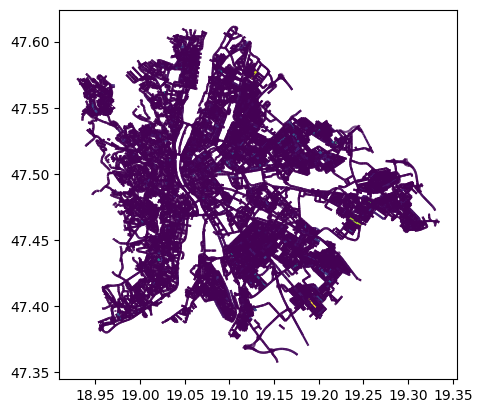

In [94]:
gdf_drive[1].merge(segment_count.to_pandas(), on="osmid").plot(column="count")

In [99]:
gdf_drive[1].merge(segment_count.to_pandas(), on="osmid").to_file(
    "../device_count.geojson"
)